In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, learning_curve
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error
from sklearn.base import clone

def rmse(actual, predicted):
    return mean_squared_error(actual, predicted)  **0.5

In [3]:
df = pd.read_csv('training_models_demo.csv')
X = df[['x']].to_numpy()
y = df['y'].to_numpy()
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=42
)
print('Train / validation / test:',
      len(X_train), len(X_valid), len(X_test))

Train / validation / test: 144 48 48


          x          y
0  2.824188  10.522462
1 -0.265342   3.016801
2 -0.246505   1.539071
3  1.094973   4.775298
4  1.433904   5.261035
<class 'pandas.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       144 non-null    float64
 1   y       144 non-null    float64
dtypes: float64(2)
memory usage: 2.4 KB
Missing values:
x    0
y    0
dtype: int64
            x       y
count  144.00  144.00
mean    -0.08    3.73
std      1.75    2.73
min     -2.92   -0.14
25%     -1.73    1.75
50%     -0.19    2.93
75%      1.45    5.16
max      2.95   10.90


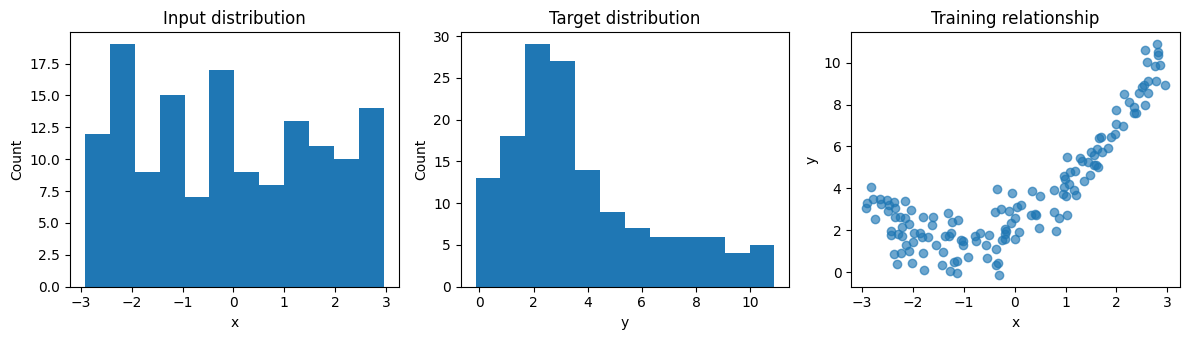

In [4]:
train_df = pd.DataFrame({'x': X_train[:, 0], 'y': y_train})
print(train_df.head())
train_df.info()
print('Missing values:')
print(train_df.isna().sum())
print(train_df.describe().round(2))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
axes[0].hist(train_df['x'], bins=12)
axes[0].set(xlabel='x', ylabel='Count', title='Input distribution')
axes[1].hist(train_df['y'], bins=12)
axes[1].set(xlabel='y', ylabel='Count', title='Target distribution')
axes[2].scatter(X_train[:, 0], y_train, alpha=0.65)
axes[2].set(xlabel='x', ylabel='y', title='Training relationship')
plt.tight_layout()
plt.show()

In [5]:
mean_prediction = float(y_train.mean())
baseline_train = np.full(len(y_train), mean_prediction)
baseline_valid = np.full(len(y_valid), mean_prediction)
print('Training mean:', round(mean_prediction, 3))
print('Baseline train RMSE:', round(rmse(y_train, baseline_train), 3))
print('Baseline valid RMSE:', round(rmse(y_valid, baseline_valid), 3))
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_valid_s = scaler.transform(X_valid)
Xb_train = np.c_[np.ones(len(X_train_s)), X_train_s]
Xb_valid = np.c_[np.ones(len(X_valid_s)), X_valid_s]
print('Design matrix:', Xb_train.shape)

Training mean: 3.734
Baseline train RMSE: 2.722
Baseline valid RMSE: 2.702
Design matrix: (144, 2)


In [6]:
def train_gd(Xb, target, rate=0.1, epochs=100):
    theta = np.zeros(Xb.shape[1])
    losses = []
    for epoch in range(epochs):
        errors = Xb @ theta - target
        gradient = (2 / len(target)) * Xb.T @ errors
        theta = theta - rate * gradient
        loss = np.mean((Xb @ theta - target) ** 2)
        losses.append(loss)
        if not np.isfinite(loss) or loss > 1e12:
            break # stop an intentionally unstable experiment
    return theta, np.array(losses)

theta_gd, losses = train_gd(Xb_train, y_train)
print('Intercept and scaled slope:', theta_gd.round(3))
print('First / last MSE:', losses[[0, -1]].round(3))
print('Validation RMSE:', round(rmse(y_valid, Xb_valid @ theta_gd), 3))

Intercept and scaled slope: [3.734 2.171]
First / last MSE: [14.637  2.694]
Validation RMSE: 1.96


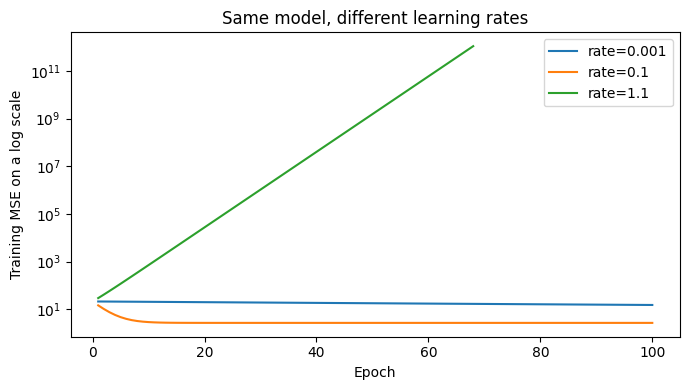

In [7]:
plt.figure(figsize=(7, 4))
for rate in [0.001, 0.1, 1.1]:
    trial_theta, trial_loss = train_gd(
        Xb_train, y_train, rate=rate, epochs=100
    )
    plt.semilogy(range(1, len(trial_loss) + 1), trial_loss,
                 label=f'rate={rate}')
plt.xlabel('Epoch')
plt.ylabel('Training MSE on a log scale')
plt.title('Same model, different learning rates')
plt.legend()
plt.tight_layout()
plt.show()

Least squares: [3.734 2.171]
Gradient descent: [3.734 2.171]
Largest parameter difference: 7.607092733508125e-10


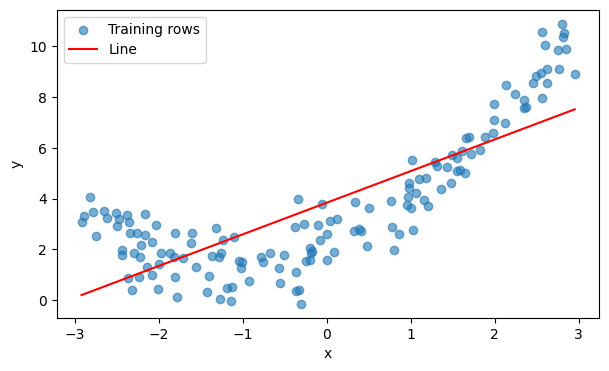

In [8]:
theta_ls = np.linalg.lstsq(Xb_train, y_train, rcond=None)[0]
print('Least squares:', theta_ls.round(3))
print('Gradient descent:', theta_gd.round(3))
print('Largest parameter difference:', np.max(np.abs(theta_ls - theta_gd)))
line_model = make_pipeline(StandardScaler(), LinearRegression())
line_model.fit(X_train, y_train)
grid = np.linspace(X_train.min(), X_train.max(), 200).reshape(-1, 1)
plt.figure(figsize=(7, 4))
plt.scatter(X_train[:, 0], y_train, alpha=0.6, label='Training rows')
plt.plot(grid[:, 0], line_model.predict(grid), color='red', label='Line')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

In [9]:
def polynomial_model(degree, alpha=0.0):
    estimator = LinearRegression() if alpha == 0 else Ridge(alpha=alpha)
    return make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        StandardScaler(), estimator
    )

models = {}
rows = []
for degree in [1, 2, 10]:
    fitted = polynomial_model(degree).fit(X_train, y_train)
    models[degree] = fitted
    rows.append({'degree': degree,
                 'train_rmse': rmse(y_train, fitted.predict(X_train)),
                 'valid_rmse': rmse(y_valid, fitted.predict(X_valid))})
comparison = pd.DataFrame(rows)
print(comparison.round(3))

   degree  train_rmse  valid_rmse
0       1       1.641       1.960
1       2       0.797       0.772
2      10       0.767       0.791


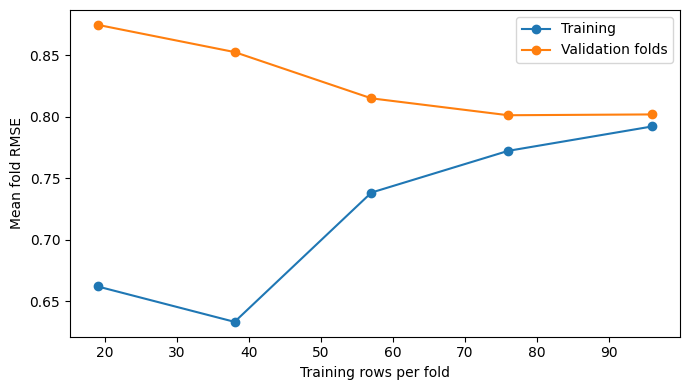

In [10]:
cv = KFold(n_splits=3, shuffle=True, random_state=42)
sizes, train_scores, valid_scores = learning_curve(
    polynomial_model(2), X_train, y_train, cv=cv,
    train_sizes=[0.2, 0.4, 0.6, 0.8, 1.0],
    scoring='neg_mean_squared_error'
)
train_errors = np.sqrt(-train_scores).mean(axis=1)
valid_errors = np.sqrt(-valid_scores).mean(axis=1)
plt.figure(figsize=(7, 4))
plt.plot(sizes, train_errors, 'o-', label='Training')
plt.plot(sizes, valid_errors, 'o-', label='Validation folds')
plt.xlabel('Training rows per fold')
plt.ylabel('Mean fold RMSE')
plt.legend()
plt.tight_layout()
plt.show()

In [11]:
candidate_settings = [(1, 0.0), (2, 0.0), (10, 0.0),
                      (10, 0.1), (10, 1.0), (10, 10.0)]
print('Candidates (degree, alpha):', candidate_settings)
# alpha=0 uses LinearRegression. Positive alpha uses Ridge.
# Keep the test set closed while comparing these candidates.

Candidates (degree, alpha): [(1, 0.0), (2, 0.0), (10, 0.0), (10, 0.1), (10, 1.0), (10, 10.0)]


In [12]:
results = []
for degree, alpha in candidate_settings:
    candidate = polynomial_model(degree, alpha).fit(X_train, y_train)
    results.append({'degree': degree, 'alpha': alpha,
                    'train_rmse': rmse(y_train, candidate.predict(X_train)),
                    'valid_rmse': rmse(y_valid, candidate.predict(X_valid))})
results = pd.DataFrame(results).sort_values('valid_rmse')
print(results.round(3).to_string(index=False))
best = results.iloc[0]
chosen_degree = int(best['degree'])
chosen_alpha = float(best['alpha'])
print('Recorded choice:', chosen_degree, chosen_alpha)

 degree  alpha  train_rmse  valid_rmse
     10    1.0       0.784       0.766
      2    0.0       0.797       0.772
     10    0.1       0.782       0.773
     10   10.0       0.821       0.785
     10    0.0       0.767       0.791
      1    0.0       1.641       1.960
Recorded choice: 10 1.0


Final test RMSE: 0.862
Frozen degree / alpha: 10 1.0


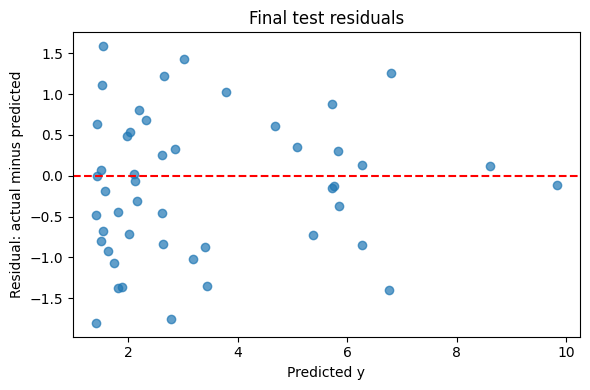

In [13]:
final_model = polynomial_model(chosen_degree, chosen_alpha)
final_model.fit(X_dev, y_dev)
test_predictions = final_model.predict(X_test)
print('Final test RMSE:', round(rmse(y_test, test_predictions), 3))
print('Frozen degree / alpha:', chosen_degree, chosen_alpha)
plt.figure(figsize=(6, 4))
plt.scatter(test_predictions, y_test - test_predictions, alpha=0.7)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Predicted y')
plt.ylabel('Residual: actual minus predicted')
plt.title('Final test residuals')
plt.tight_layout()
plt.show()